In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style = "whitegrid")

In [2]:
df = pd.read_csv("C:\\Users\\HP\\OneDrive\\文档\\GitHub\\internship\\week_8\\capstone-churn-analysis\\data\\cleaned_data.csv")

print("Dataset loaded successfully!!")
print("Dataset shape :: ", df.shape)

Dataset loaded successfully!!
Dataset shape ::  (500, 9)


In [3]:
total_customers = len(df)

churned_customers = df["Churn"].sum()

retained_customers = total_customers - churned_customers

churn_rate = (churned_customers / total_customers) * 100

retention_rate = (retained_customers / total_customers) * 100

average_tenure = df["Tenure"].mean()

print("Total Customers :: ", total_customers)
print("Churned Customers :: ", churned_customers)
print("Retained Customers :: ", retained_customers)
print("Churn Rate :: ", round(churn_rate,2), "%")
print("Retention Rate :: ", round(retention_rate,2), "%")
print("Average Tenure :: ", round(average_tenure,2), "months")

Total Customers ::  500
Churned Customers ::  53
Retained Customers ::  447
Churn Rate ::  10.6 %
Retention Rate ::  89.4 %
Average Tenure ::  36.53 months


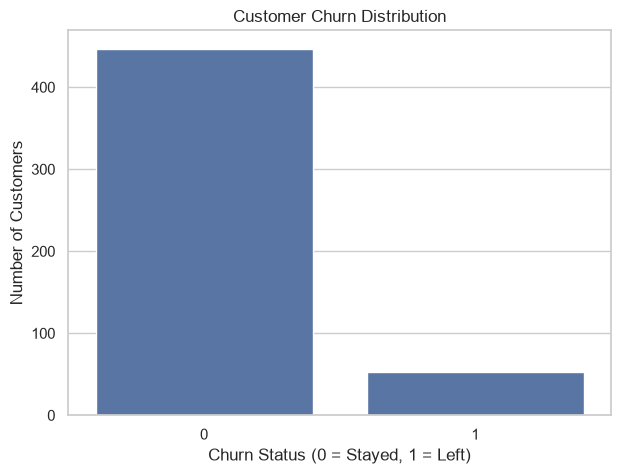

In [5]:
plt.figure(figsize = (7,5))

sns.countplot(data = df, x = "Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")

plt.show()

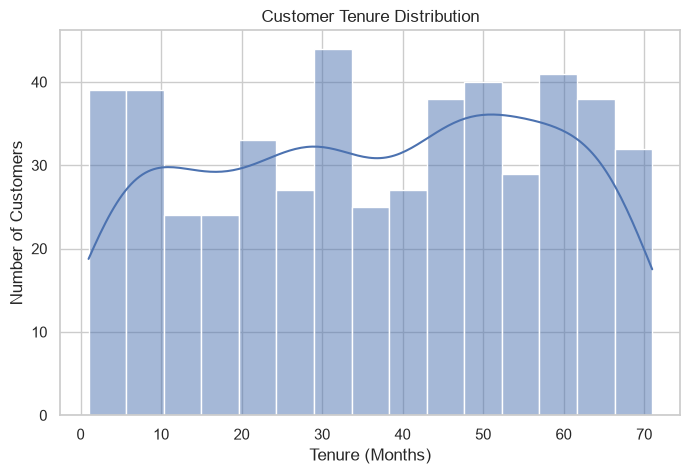

In [6]:
plt.figure(figsize = (8,5))

sns.histplot(data = df, x = "Tenure", bins = 15, kde = True)

plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

In [7]:
df["Tenure"].value_counts(
    bins = [0,15,30,45,60,100]
).sort_index()

(-0.001, 15.0]    110
(15.0, 30.0]       94
(30.0, 45.0]       99
(45.0, 60.0]      118
(60.0, 100.0]      79
Name: count, dtype: int64

Insight 1 – Customer Tenure: The 46–60 month tenure group contains the highest number of customers (118). This indicates a substantial established customer segment. The company should investigate the characteristics of these long-term customers and compare them with recently acquired customers.

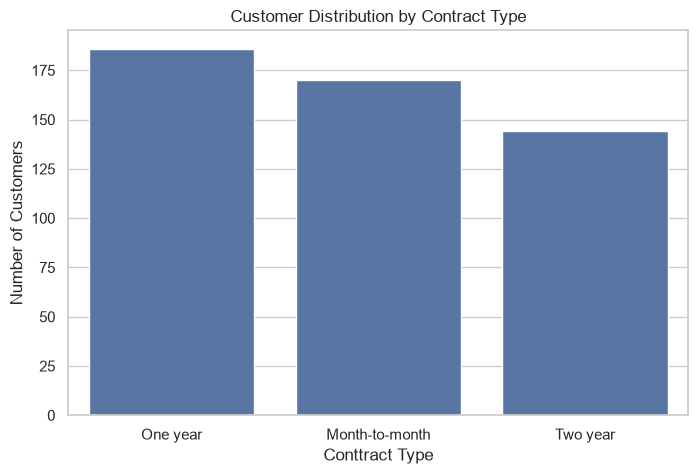

In [8]:
plt.figure(figsize = (8,5))

sns.countplot(
    data = df,
    x = "Contract",
    order = df["Contract"].value_counts().index
)

plt.title("Customer Distribution by Contract Type")
plt.xlabel("Conttract Type")
plt.ylabel("Number of Customers")

plt.show()

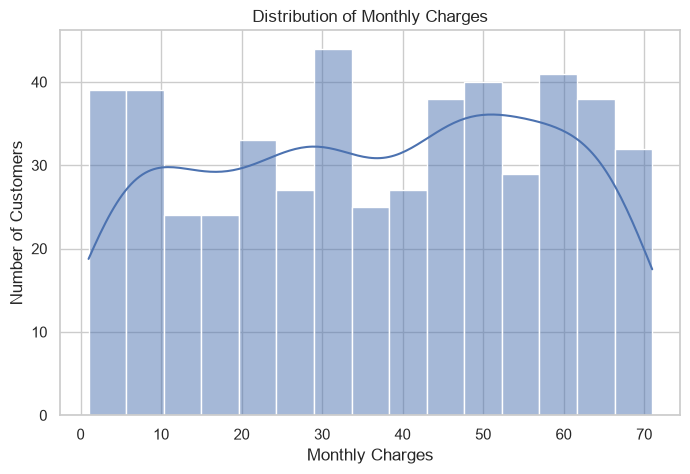

In [9]:
plt.figure(figsize = (8,5))

sns.histplot(data = df, x = "Tenure", bins = 15, kde = True)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

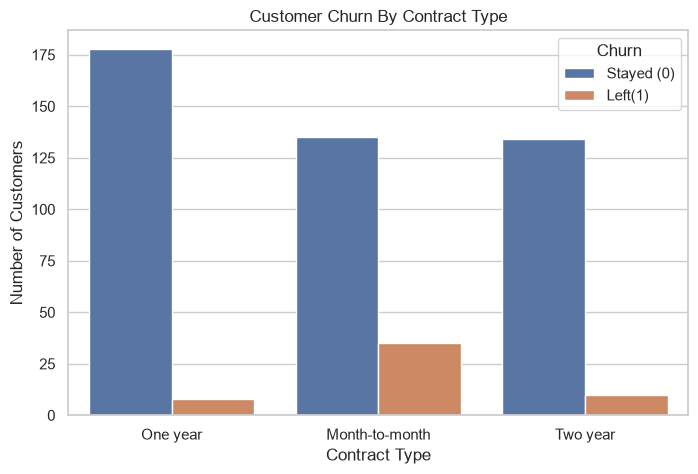

In [11]:
plt.figure(figsize = (8,5))

sns.countplot(
    data = df,
    x = "Contract",
    hue = "Churn"
)

plt.title("Customer Churn By Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.legend(
    title = "Churn",
    labels = ["Stayed (0)","Left(1)"]
)

plt.show()

In [12]:
contract_churn = df.groupby("Contract")["Churn"].mean() * 100

print(contract_churn.round(2))

Contract
Month-to-month    20.59
One year           4.30
Two year           6.94
Name: Churn, dtype: float64


### Finding: Contract-wise Customer Churn

Month-to-month customers have the highest churn rate at 20.59%, compared with 4.30% for one-year contracts and 6.94% for two-year contracts.

This suggests that customers with shorter contractual commitments may be more likely to leave. The company should investigate the reasons for this churn and consider targeted retention strategies.

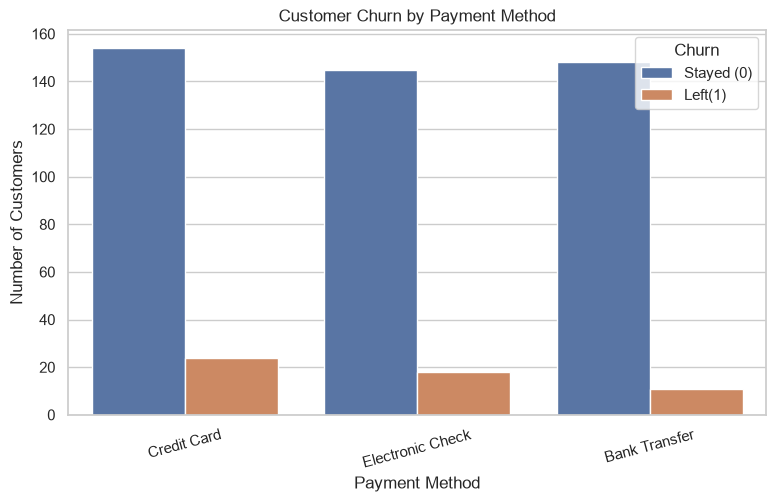

In [13]:
plt.figure(figsize = (9,5))

sns.countplot(
    data = df,
    x = "PaymentMethod",
    hue = "Churn"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation = 15)
plt.legend(
    title = "Churn",
    labels = ["Stayed (0)", "Left(1)"]
)

plt.show()

In [14]:
df.groupby("PaymentMethod")["Churn"].sum()

PaymentMethod
Bank Transfer       11
Credit Card         24
Electronic Check    18
Name: Churn, dtype: int64

In [15]:
payment_churn = df.groupby("PaymentMethod")["Churn"].mean() * 100

print(payment_churn.round(2))

PaymentMethod
Bank Transfer        6.92
Credit Card         13.48
Electronic Check    11.04
Name: Churn, dtype: float64


### Finding: Payment Method-wise Customer Churn

Credit Card customers have the highest churn rate at 13.48%, followed by Electronic Check customers at 11.04%. Bank Transfer customers have the lowest churn rate at 6.92%.

The company should investigate whether payment experience, billing preferences, or other customer characteristics are associated with this difference.

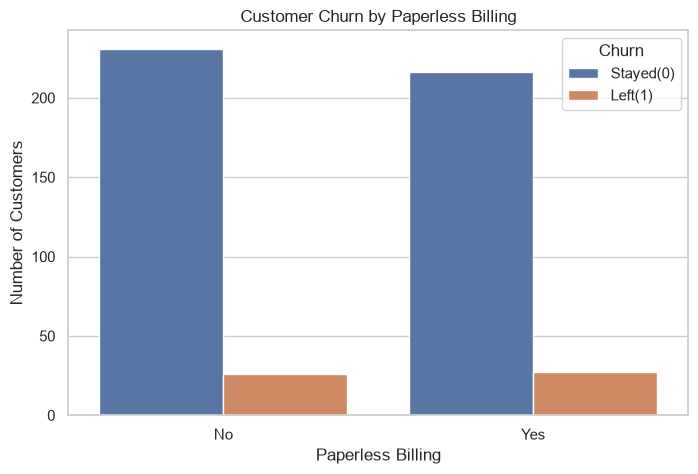

In [16]:
plt.figure(figsize = (8,5))

sns.countplot(
    data = df,
    x = "PaperlessBilling",
    hue = "Churn"
)

plt.title("Customer Churn by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Number of Customers")
plt.legend(
    title = "Churn",
    labels = ["Stayed(0)","Left(1)"]
)

plt.show()

In [17]:
df.groupby("PaperlessBilling")["Churn"].sum()

PaperlessBilling
No     26
Yes    27
Name: Churn, dtype: int64

In [18]:
billing_churn = df.groupby("PaperlessBilling")["Churn"].mean() * 100

print(billing_churn.round(2))

PaperlessBilling
No     10.12
Yes    11.11
Name: Churn, dtype: float64


### Finding: Paperless Billing-wise Customer Churn

Customers using paperless billing have a churn rate of 11.11%, compared with 10.12% among customers not using paperless billing.

The difference is relatively small. Further investigation is required before determining whether billing preferences are meaningfully associated with customer churn.

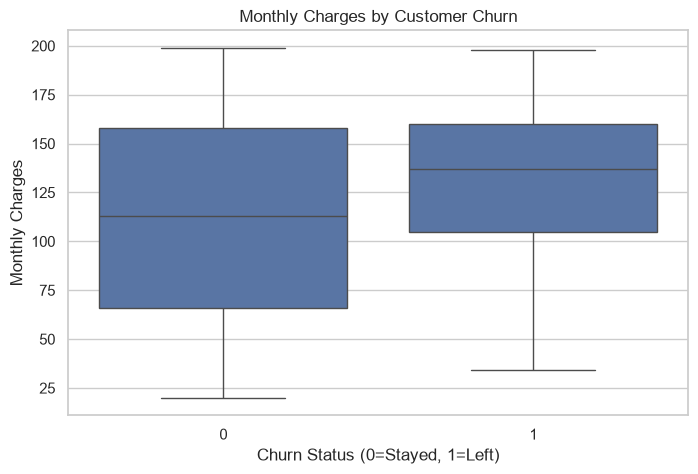

In [20]:
plt.figure(figsize = (8,5))

sns.boxplot(
    data = df,
    x = "Churn",
    y = "MonthlyCharges"
)

plt.title("Monthly Charges by Customer Churn")
plt.xlabel("Churn Status (0=Stayed, 1=Left)")
plt.ylabel("Monthly Charges")

plt.show()

In [21]:
df.groupby("Churn")["MonthlyCharges"].mean().round(2)

Churn
0    111.72
1    129.77
Name: MonthlyCharges, dtype: float64

### Finding: Monthly Charges vs Customer Churn

Customers who left had average monthly charges of 129.77, while customers who stayed had average monthly charges of 111.72.

This indicates that higher monthly charges are associated with customer churn in this dataset. The company should review pricing, plan value, and customer affordability to identify possible retention opportunities.

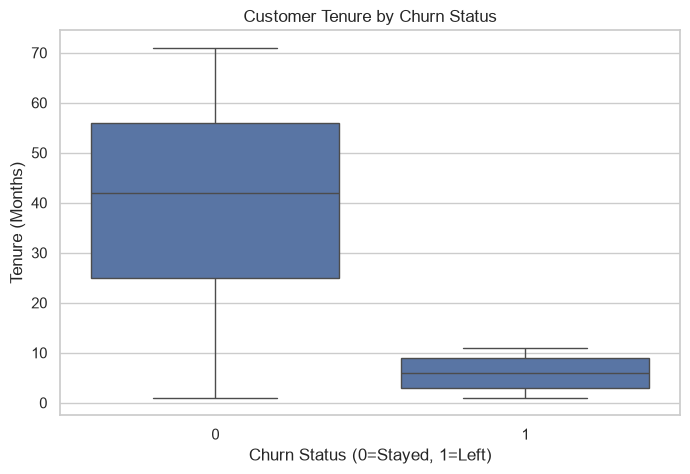

In [22]:
plt.figure(figsize = (8,5))

sns.boxplot(
    data = df,
    x = "Churn",
    y = "Tenure"
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn Status (0=Stayed, 1=Left)")
plt.ylabel("Tenure (Months)")

plt.show()

In [23]:
df.groupby("Churn")["Tenure"].mean().round(2)

Churn
0    40.15
1     6.00
Name: Tenure, dtype: float64

### Finding: Customer Tenure vs Churn

Customers who left had an average tenure of 6 months, whereas customers who stayed had an average tenure of 40.15 months.

This indicates that recently acquired customers may be at greater risk of churn. The company should strengthen its onboarding process, provide early customer support, and monitor new customers during their first few months.

In [25]:
correlation = df[
    ["Tenure","MonthlyCharges","TotalCharges", "Churn"]
].corr()

print(correlation.round(2))

                Tenure  MonthlyCharges  TotalCharges  Churn
Tenure            1.00           -0.06         -0.01  -0.51
MonthlyCharges   -0.06            1.00         -0.04   0.11
TotalCharges     -0.01           -0.04          1.00   0.00
Churn            -0.51            0.11          0.00   1.00


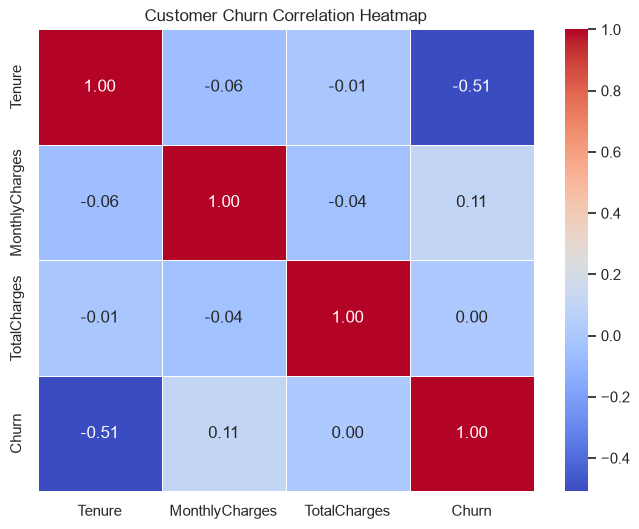

In [28]:
plt.figure(figsize = (8,6))

sns.heatmap(
    correlation,
    annot = True,
    cmap = "coolwarm",
    fmt = ".2f",
    linewidths = 0.5
)

plt.title("Customer Churn Correlation Heatmap")
plt.show()

### Finding: Correlation Analysis

The correlation analysis shows that Tenure has the strongest relationship with Churn, with a correlation coefficient of -0.51. This indicates a moderate negative relationship, suggesting that customers with longer tenure tend to be less likely to leave.

MonthlyCharges has a weak positive correlation with Churn (0.11), while TotalCharges has almost no linear correlation with Churn (0.00).

Tenure appears to be an important variable for understanding customer churn. However, correlation does not establish causation.